# LeNet-5 Neural Network for MNIST


### Options


In [1]:
batch_size = 20
EPOCHS = 20

### Setup our model


In [2]:
from torch import nn
import torch

import brevitas.nn as qnn
from brevitas.core.quant import QuantType
import torch.nn.functional as F


import brevitas.nn as qnn
from brevitas.quant import Int32Bias, Int8Bias, Int8BiasPerTensorFloatInternalScaling


class QuantLeNet(nn.Module):
    
    def __init__(self):
        super(QuantLeNet, self).__init__()
        self.quant_inp = qnn.QuantIdentity(bit_width=8, return_quant_tensor=True)
        self.conv1 = qnn.QuantConv2d(1, 6, 5, bias=True, weight_bit_width=8, bias_quant=Int8BiasPerTensorFloatInternalScaling)
        self.relu1 = qnn.QuantReLU(bit_width=8, return_quant_tensor=True)
        self.conv2 = qnn.QuantConv2d(6, 16, 5, bias=True, weight_bit_width=8, bias_quant=Int8BiasPerTensorFloatInternalScaling)
        self.relu2 = qnn.QuantReLU(bit_width=8, return_quant_tensor=True)
        self.fc1   = qnn.QuantLinear(16*5*5, 120, bias=True, weight_bit_width=8, bias_quant=Int8BiasPerTensorFloatInternalScaling)
        self.fc2   = qnn.QuantLinear(120, 84, bias=True, weight_bit_width=8, bias_quant=Int8BiasPerTensorFloatInternalScaling)
        self.fc3   = qnn.QuantLinear(84, 10, bias=True, weight_bit_width=8, bias_quant=Int8BiasPerTensorFloatInternalScaling)

    def forward(self, x):
        out = self.quant_inp(x)
        out = self.relu1(self.conv1(out))
        out = F.max_pool2d(out, 2)
        out = self.relu2(self.conv2(out))
        out = F.max_pool2d(out, 2)
        out = out.reshape(out.shape[0], -1)
        out = self.fc1(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

model = QuantLeNet()
print(model)

QuantLeNet(
  (quant_inp): QuantIdentity(
    (input_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
    )
    (act_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
      (fused_activation_quant_proxy): FusedActivationQuantProxy(
        (activation_impl): Identity()
        (tensor_quant): RescalingIntQuant(
          (int_quant): IntQuant(
            (float_to_int_impl): RoundSte()
            (tensor_clamp_impl): TensorClamp()
            (delay_wrapper): DelayWrapper(
              (delay_impl): _NoDelay()
            )
            (input_view_impl): Identity()
          )
          (scaling_impl): ParameterFromRuntimeStatsScaling(
            (stats_input_view_shape_impl): OverTensorView()
            (stats): _Stats(
              (stats_impl): AbsPercentile()
            )
            (restrict_scaling_impl): FloatRestrictValue()
            (restrict_scaling): _RestrictValue(
              (restrict_value_impl): Fl

In [3]:
import torch

use_gpu = torch.cuda.is_available()
if use_gpu:
    model = model.cuda()
    print("USE GPU")
else:
    print("USE CPU")

USE CPU


### Setting up the data


In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose(
    [transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
    transforms.Pad(padding=[2,2])])


training_set = torchvision.datasets.MNIST('./data', train=True, transform=transform, download=True)
validation_set = torchvision.datasets.MNIST('./data', train=False, transform=transform, download=True)

training_loader = torch.utils.data.DataLoader(training_set, batch_size=4, shuffle=True)
validation_loader = torch.utils.data.DataLoader(validation_set, batch_size=4, shuffle=False)

classes = ('0', '1', '2', '3', '4',
        '5', '6', '7', '8', '9')

# Report split sizes
print('Training set has {} instances'.format(len(training_set)))
print('Validation set has {} instances'.format(len(validation_set)))


Training set has 60000 instances
Validation set has 10000 instances


## Exporting of Data

In [ ]:
import numpy as np

x_val = []
y_val = []

x_train = []
y_train = []

for (x, y) in validation_set:
    x_val.append(x.detach().numpy())
    tmp = np.full(shape=(10, ), fill_value=0)
    tmp[y] = 1
    y_val.append(tmp)

for (x, y) in training_set:
    x_train.append(x.detach().numpy())
    tmp = np.full(shape=(10, ), fill_value=0)
    tmp[y] = 1
    y_train.append(tmp)

x_val = np.array(x_val, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
x_train = np.array(x_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

print(np.shape(x_val), np.shape(y_val))
print(np.shape(x_train), np.shape(y_val))

np.save("./export/mnist/x_test.npy", x_val)
np.save("./export/mnist/y_test.npy", y_val)
np.save("./export/mnist/x_train.npy", x_train)
np.save("./export/mnist/y_train.npy", y_train)

(10000, 1, 32, 32) (10000, 10)
(60000, 1, 32, 32) (10000, 10)


## Visualization of Data

8  9  2  7


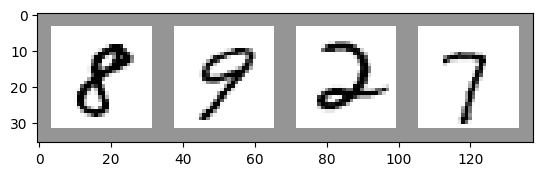

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Helper function for inline image display
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

dataiter = iter(training_loader)
images, labels = next(dataiter)

# Create a grid from the images and show them
img_grid = torchvision.utils.make_grid(images)
matplotlib_imshow(img_grid, one_channel=True)
print('  '.join(classes[labels[j]] for j in range(4)))

## Training

In [7]:
from torch.autograd import Variable
import datetime as d
from torch.utils.tensorboard import SummaryWriter

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

def train_one_epoch(epoch_index, tb_writer):
    running_loss = 0.
    last_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for i, data in enumerate(training_loader):
        # Every data instance is an input + label pair
        inputs, labels = data

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = loss_fn(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()
        if i % 1000 == 999:
            last_loss = running_loss / 1000 # loss per batch
            print('  batch {} loss: {}'.format(i + 1, last_loss))
            tb_x = epoch_index * len(training_loader) + i + 1
            tb_writer.add_scalar('Loss/train', last_loss, tb_x)
            running_loss = 0.

    return last_loss

# Initializing in a separate cell so we can easily add more epochs to the same run
timestamp = d.datetime.now().strftime('%Y%m%d_%H%M%S')
writer = SummaryWriter('runs/fashion_trainer_{}'.format(timestamp))
epoch_number = 0

best_vloss = 1_000_000.

for epoch in range(EPOCHS):
    print('EPOCH {}:'.format(epoch_number + 1))

    # Make sure gradient tracking is on, and do a pass over the data
    model.train(True)
    avg_loss = train_one_epoch(epoch_number, writer)


    running_vloss = 0.0
    # Set the model to evaluation mode, disabling dropout and using population
    # statistics for batch normalization.
    model.eval()

    # Disable gradient computation and reduce memory consumption.
    with torch.no_grad():
        for i, vdata in enumerate(validation_loader):
            vinputs, vlabels = vdata
            voutputs = model(vinputs)
            vloss = loss_fn(voutputs, vlabels)
            running_vloss += vloss

    avg_vloss = running_vloss / (i + 1)
    print('LOSS train {} valid {}'.format(avg_loss, avg_vloss))

    # Log the running loss averaged per batch
    # for both training and validation
    writer.add_scalars('Training vs. Validation Loss',
                    { 'Training' : avg_loss, 'Validation' : avg_vloss },
                    epoch_number + 1)
    writer.flush()

    # Track best performance, and save the model's state
    if avg_vloss < best_vloss:
        best_vloss = avg_vloss
        model_path = 'model_{}_{}'.format(timestamp, epoch_number)
        torch.save(model.state_dict(), model_path)

    epoch_number += 1

2024-12-06 21:18:48.991858: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1733516329.075417   56489 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1733516329.099851   56489 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-06 21:18:49.278279: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


EPOCH 1:


/home/markus/.venv/lib/python3.12/site-packages/torch/_tensor.py:1488: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at ../c10/core/TensorImpl.h:1928.)
  return super().rename(names)
/home/markus/.venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:549: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at ../torch/csrc/utils/python_arg_parser.cpp:311.)
  return F.conv2d(


  batch 1000 loss: 2.2876722025871277


KeyboardInterrupt: 

In [ ]:
## This part is probably complettly unnecessary but I dont care

total_correct = 0
total_samples = 0

for images, labels in validation_loader:
        # Move the data to the device (CPU or GPU)

        # Forward pass
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

    # Update the running total of correct predictions and samples
    total_correct += (predicted == labels).sum().item()
    total_samples += labels.size(0)

# Calculate the accuracy for this epoch
accuracy = 100 * total_correct / total_samples
print(f'Accuracy = {accuracy:.2f}%')

Accuracy = 98.85%


## Export model

In [ ]:
import brevitas.onnx as bo

exported_model = bo.export_qonnx(model, args=torch.randn(1, 1, 32, 32), export_path="Lenet_qonnx.onnx", opset_version=13)